# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

  


# Importing Packages & Loading Dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Loading the penguins dataset for later analysis
df = sns.load_dataset('penguins')

In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


# Defining the Analysis Class
Six methods are used for analysis. They cover numerical and categorical variables.

In [12]:
class DataAnalyzer:
    """Univariate & Bivariate Exploratory Data Analysis"""

#defining the class first 
    def __init__(self, data):
        self.df = data.copy()
        print("Dataset shape:", self.df.shape)
        print("Columns:", self.df.columns)
        
#numerical summary using univariate analysis
    def num_summary(self, column):
        """Calculate Descriptive Stats for a numerical column"""
        values = self.df[column].dropna()
        summary = values.describe().round(3)
        print(f"Summary statistics for {column}:")
        print(summary)
        print(f"Missing values in {column}: {self.df[column].isna().sum()}")
        return summary
        
#categorical distribution using univariate analysis
    def cat_distribution(self, column):
        """Show Category Counts & a Countplot"""
        counts = self.df[column].value_counts(dropna=False)
        print(f"Counts for {column}:")
        print(counts)
        plt.figure(figsize=(7, 5))
        sns.countplot( data=self.df, x=column, order=self.df[column].value_counts().index, color="violet")
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Number of Penguins")
        plt.show()
        return counts
        
#bivariate analysis of two numerical variables
    def quant_quant(self, x, y):
        """Print Pearson correlation and plot two numeric variables."""
        pair = self.df[[x, y]].dropna()
        correlation = pair[x].corr(pair[y])
        print(f"Pearson correlation between {x} and {y} is {correlation:.3f}")
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=pair, x=x, y=y, color="pink")
        plt.title(f"{x} vs. {y}")
        plt.show()
        return correlation
        
#numerical distribution using univariate analysis
    def num_distribution(self, column): 
        """Create a histogram showing the distribution of a numerical variable."""
        plt.figure(figsize=(7, 5))
        sns.histplot(data=self.df, x=column, bins=20, kde=True, color="pink")
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Number of penguins")
        plt.show() 
        
#Bivariate analysis of a categorical and a numerical variable
    def num_cat(self, category, quantity):
        """Compare and Contrast Numeric distribution throughout categories using averages and boxplot diagram"""
        averages = self.df.groupby(category)[quantity].mean().round(3)
        print(f"Average {quantity} for each {category}:")
        print(averages)
        plt.figure(figsize=(7, 5))
        sns.boxplot(data=self.df, x=category, y=quantity, color="violet")
        plt.title(f"{quantity} by {category}")
        plt.xlabel(category)
        plt.ylabel(quantity)
        plt.show()
        return averages
        
#Bivariate analysis of two categorical variables
    def cat_cat(self, r_category, c_category):
        """Compare two categorical variables with counts and within-row percentages in a contingency table"""
        counts = pd.crosstab(self.df[r_category], self.df[c_category])
        row_percentages = pd.crosstab( self.df[r_category], self.df[c_category], normalize="index").mul(100).round(3)
        print("Frequency table:")
        print(counts)
        print("\nPercentages in each row category:")
        print(row_percentages)
        return counts, row_percentages

# Creating an instance of the class

In [13]:
analysis = DataAnalyzer(df) 

Dataset shape: (344, 7)
Columns: Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='str')


## Analysis One 
**Question**: What is the average flipper length of penguins in this dataset, and how much does it vary among individual penguins?

In this analysis, I want to find the average flipper length of penguins in the dataset and examine how much their flipper lengths vary.

In [14]:
flipper_length_summary = analysis.num_summary('flipper_length_mm')

Summary statistics for flipper_length_mm:
count    342.000
mean     200.915
std       14.062
min      172.000
25%      190.000
50%      197.000
75%      213.000
max      231.000
Name: flipper_length_mm, dtype: float64
Missing values in flipper_length_mm: 2


### Answer: 
The average flipper length in this dataset is around 200.915mm. The median is 197mm.  The standard deviation is 14.06 mm, therefore we can conclude that there is some variation in the flipper length among the penguins. The shortest length is 172mm and the longest length is 231mm. The middle 50% of recorded flipper lengths fall between 190 mm and 213 mm.

## Analysis Two
**Question**: How many penguins belong to each species? 

This analysis will find out how many penguins of each species are there and determine which species has the most frequent number of recorded penguins.

Counts for species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


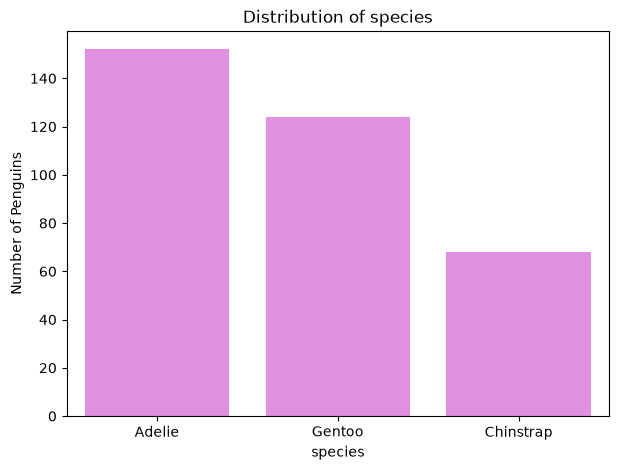

In [15]:
species_count = analysis.cat_distribution("species")

### Answer: 
There are 152 Adelie penguins, 124 Gentoo penguins, and 68 Chinstrap penguins in the dataset. Adelie is the most frequently recorded species, while Chinstrap is the least frequently recorded.

## Analysis Three 
**Question**: Is there a relationship between the bill length and bill depth of the penguins? How strong is this relationship, and is it positive or negative? 

In this analysis, I will investigate whether there is a relationship between penguins' bill length and bill depth. I will use Pearson's correlation coefficient and a scatterplot to examine the strength and direction of this relationship.

Pearson correlation between bill_length_mm and bill_depth_mm is -0.235


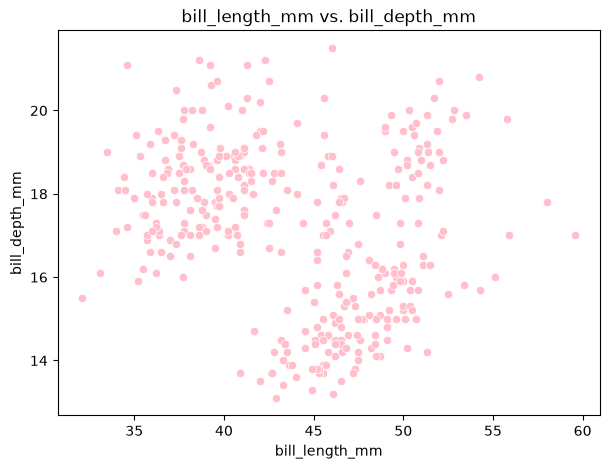

In [16]:
bill_length_correlation = analysis.quant_quant('bill_length_mm', 'bill_depth_mm')

### Answer:
The Pearson correlation coefficient between bill length and bill depth is around -0.235. This shows a weak negative linear relationship between the two variables. We can therefore infer that penguins with longer bills tend to have slightly shallower bills. However, because the correlation coefficient is relatively close to zero, the relationship isn't strong.

## Analysis Four 
**Question**: What does the distribution of flipper lengths look like?

In this analysis, I want to find out how flipper lengths are distributed among penguins using a histogram and I will determine whether their measurements are concentrated close to similar values or not.

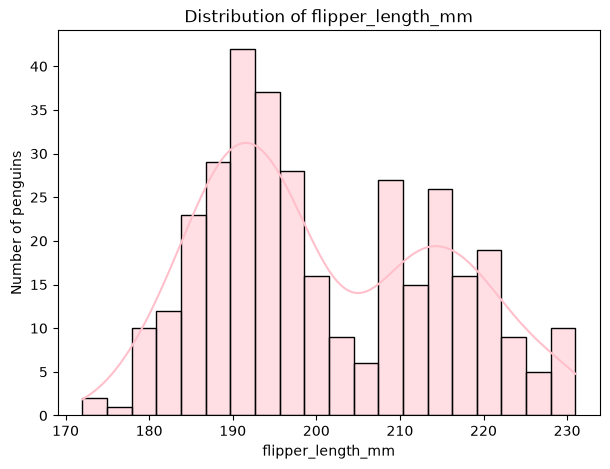

In [17]:
flippers_distribution = analysis.num_distribution("flipper_length_mm")

### Answer: 
The histogram shows that flipper lengths aren't evenly distributed, with the range starting from 172mm to ending at 231mm. There is some concentration near the mid-point of the range, which suggests the possibility that there may be specific groups of penguins with specific flipper lengths.

## Analysis Five 
**Question**: Does the average body mass of penguins vary depending on which island they inhabit? How does the distribution of body mass differ across the three islands?

In this analysis, the average body mass of penguins across Biscoe, Dream, and Torgersen Islands will be compared using a boxplot. I also want to examine how the distribution of body mass differs across these islands.

Average body_mass_g for each island:
island
Biscoe       4716.018
Dream        3712.903
Torgersen    3706.373
Name: body_mass_g, dtype: float64


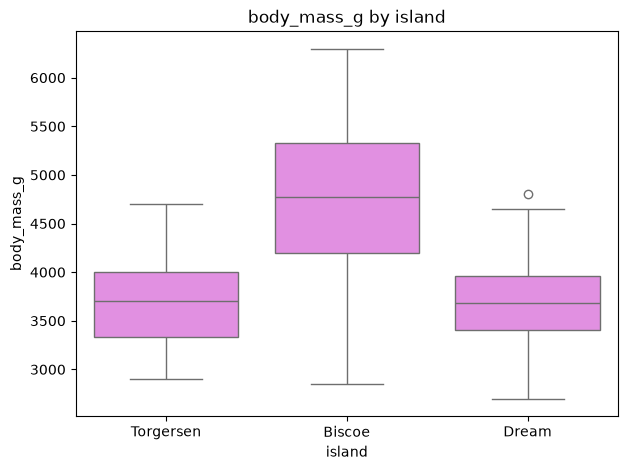

In [18]:
body_mass_by_island = analysis.num_cat('island', 'body_mass_g')

### Answer: 
The average body mass across the three islands vary. Penguins on the Biscoe Island have the greatest average body mass at 4716grams, whereas penguins on Dream and Torgersen Islands have much lower averages of approximately 3713 grams and 3706 grams, respectively. This doesn't however prove that the islands have an effect on body mass.

## Analysis Six 
**Question**: Does the proportion of male and female penguins vary across the three penguin species? Are some species represented by more males or females than others in this dataset?

In this analysis, I want to compare the proportions of male and female penguins across the three species and find out whether any species has a higher proportion of one sex than the other.

In [19]:
sex_by_species = analysis.cat_cat("species", "sex")

Frequency table:
sex        Female  Male
species                
Adelie         73    73
Chinstrap      34    34
Gentoo         58    61

Percentages in each row category:
sex        Female    Male
species                  
Adelie     50.000  50.000
Chinstrap  50.000  50.000
Gentoo     48.739  51.261


### Answer: 
There are an equal number of male and female Adelie and Chinstrap penguins. Males make up about 51.26% of Gentoo penguins, while females make up 48.739%. Overall, the sex distribution across species doesn't have major differences in numbers.